In [1]:
import numpy as np
from sklearn.tree import DecisionTreeClassifier

In [2]:
X_toy = np.array([[1], [2], [3], [4], [5], [6], [7], [8], [9], [10]])

y_toy = np.array([0, 0, 0, 1, 1, 1, 2, 2, 2, 0])

In [3]:
N = 10
K = 3

In [ ]:
#Initial sample weights (everyone starts equal: 1/N)
w = np.ones(N) / N

In [5]:
print("--- 1. Initial Sample Weights ---")
print(np.round(w, 3))

--- 1. Initial Sample Weights ---
[0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1]


In [6]:
tree = DecisionTreeClassifier(max_depth=1)
tree.fit(X_toy, y_toy, sample_weight=w)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",1
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples 

In [7]:
preds = tree.predict(X_toy)
print("\n--- 2. Weak Learner Predictions vs Actual ---")
print("Preds :", preds)
print("Actual:", y_toy)


--- 2. Weak Learner Predictions vs Actual ---
Preds : [0 0 0 1 1 1 1 1 1 1]
Actual: [0 0 0 1 1 1 2 2 2 0]


In [8]:
is_wrong = (preds != y_toy)
err = np.sum(w[is_wrong])

In [9]:
if err >= (1.0 - 1.0/K):
    print("Error is worse than random! We would break the loop here.")
elif err == 0:
    print("Perfect accuracy! We would stop boosting.")
else:
    # 6. Calculate Alpha_t
    
    alpha = np.log((1.0 - err) / err) + np.log(K - 1)
    print(f"\n--- 4. Alpha_t ---")
    print(f"{alpha:.3f}")
    
    # 7. Update normalized weights
    w_new = w * np.exp(alpha * is_wrong)
    
    # Normalize so they sum to 1
    w_new = w_new / np.sum(w_new)
    
    print("\n--- 5. Updated Normalised Weights ---")
    print(np.round(w_new, 3))


--- 4. Alpha_t ---
1.099

--- 5. Updated Normalised Weights ---
[0.056 0.056 0.056 0.056 0.056 0.056 0.167 0.167 0.167 0.167]


In [10]:
import matplotlib.pyplot as plt

In [33]:
# --- DATA LOADING ---
data1 = np.load('dat_split.npz')
X_train = data1['X_train']
y_train = data1['y_train']
X_val = data1['X_val']
y_val = data1['y_val']
X_test_clean = data1['X_test_clean']
y_test = data1['y_test']

In [13]:
N = len(X_train)
K = 40 # 40 people in Olivetti Faces

depths = [1, 2, 3, 4]
rounds_to_check = [10, 25, 50, 100]

best_val_acc = 0
best_params = {}


best_models = []
best_alphas = []
best_history = {}

In [ ]:
print("Training SAMME AdaBoost... This takes about 1-2 minutes.\n")


def predict_samme(models, alphas, X):
    scores = np.zeros((len(X), K))
    for tree, alpha in zip(models, alphas):
        preds = tree.predict(X)
        # Add the tree's alpha to the vote score of the predicted class
        scores[np.arange(len(X)), preds] += alpha
    return np.argmax(scores, axis=1)

Training SAMME AdaBoost... This takes about 1-2 minutes.



In [16]:
for d in depths:
    w = np.ones(N) / N
    models = []
    alphas = []
    
    # Trackers for the plots
    err_hist = []
    alpha_hist = []
    max_w_hist = []
    top10_w_hist = []
    
    for t in range(100):
        # 1. Train weak learner
        tree = DecisionTreeClassifier(max_depth=d, random_state=t)
        tree.fit(X_train, y_train, sample_weight=w)
        
        preds = tree.predict(X_train)
        is_wrong = (preds != y_train)
        
        # 2. Weighted error
        err = np.sum(w[is_wrong])
        
        # 3. Explicit check for worse than random (random error = 39/40 = 0.975)
        if err >= (1.0 - 1.0/K):
            print(f"Depth {d} hit worse than random error at round {t+1}. Stopping early.")
            break
            
        # Prevent division by zero if error is exactly 0
        if err == 0:
            err = 1e-10
            
        # 4. Calculate Alpha
        alpha = np.log((1.0 - err) / err) + np.log(K - 1)
        
        models.append(tree)
        alphas.append(alpha)
        
        # Save plot metrics
        err_hist.append(err)
        alpha_hist.append(alpha)
        max_w_hist.append(np.max(w))
        
        # Get the sum of the 10 heaviest weights
        sorted_w = np.sort(w)
        top10_w_hist.append(np.sum(sorted_w[-10:]))
        
        # 5. Update weights
        w = w * np.exp(alpha * is_wrong)
        w = w / np.sum(w)
        
        # 6. Check validation accuracy at the required rounds
        if (t + 1) in rounds_to_check:
            val_preds = predict_samme(models, alphas, X_val)
            val_acc = np.mean(val_preds == y_val)
            
            print(f"Depth: {d}, Rounds: {t+1:<3} | Val Acc: {val_acc:.3f}")
            
            if val_acc > best_val_acc:
                best_val_acc = val_acc
                best_params = {'depth': d, 'rounds': t+1}
                best_models = list(models) # copy the list
                best_alphas = list(alphas)
                best_history = {
                    'err': list(err_hist),
                    'alpha': list(alpha_hist),
                    'max_w': list(max_w_hist),
                    'top10_w': list(top10_w_hist)
                }

Depth: 1, Rounds: 10  | Val Acc: 0.037
Depth: 1, Rounds: 25  | Val Acc: 0.087
Depth: 1, Rounds: 50  | Val Acc: 0.100
Depth: 1, Rounds: 100 | Val Acc: 0.113
Depth: 2, Rounds: 10  | Val Acc: 0.062
Depth: 2, Rounds: 25  | Val Acc: 0.113
Depth: 2, Rounds: 50  | Val Acc: 0.125
Depth: 2, Rounds: 100 | Val Acc: 0.113
Depth: 3, Rounds: 10  | Val Acc: 0.175
Depth: 3, Rounds: 25  | Val Acc: 0.125
Depth: 3, Rounds: 50  | Val Acc: 0.237
Depth: 3, Rounds: 100 | Val Acc: 0.263
Depth: 4, Rounds: 10  | Val Acc: 0.250
Depth: 4, Rounds: 25  | Val Acc: 0.325
Depth: 4, Rounds: 50  | Val Acc: 0.375
Depth: 4, Rounds: 100 | Val Acc: 0.425


--------------------------------------------------
FROZEN MODEL: Depth 4, Rounds 100 with Val Acc 0.425


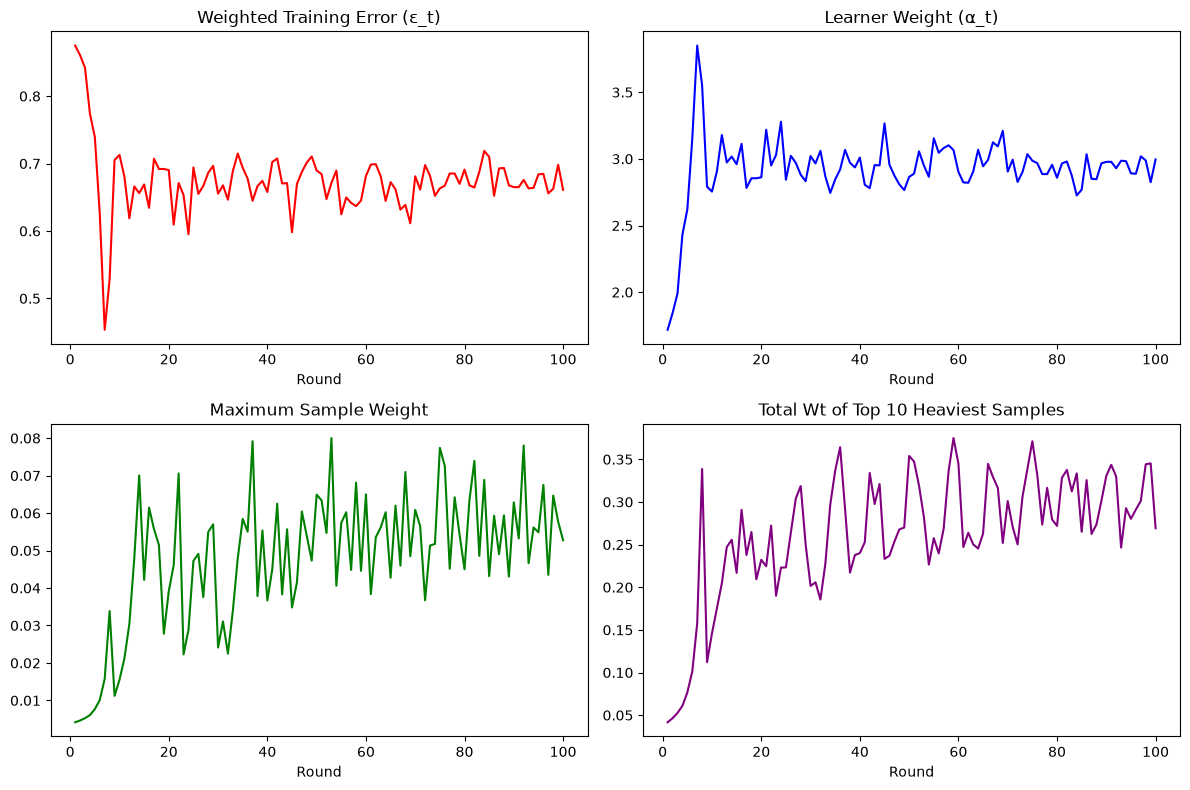

In [17]:
print("-" * 50)
print(f"FROZEN MODEL: Depth {best_params['depth']}, Rounds {best_params['rounds']} with Val Acc {best_val_acc:.3f}")

# --- Plotting the 4 requested metrics for the selected model ---
t_steps = range(1, best_params['rounds'] + 1)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].plot(t_steps, best_history['err'], color='red')
axes[0, 0].set_title("Weighted Training Error (\u03B5_t)")
axes[0, 0].set_xlabel("Round")

axes[0, 1].plot(t_steps, best_history['alpha'], color='blue')
axes[0, 1].set_title("Learner Weight (\u03B1_t)")
axes[0, 1].set_xlabel("Round")

axes[1, 0].plot(t_steps, best_history['max_w'], color='green')
axes[1, 0].set_title("Maximum Sample Weight")
axes[1, 0].set_xlabel("Round")

axes[1, 1].plot(t_steps, best_history['top10_w'], color='purple')
axes[1, 1].set_title("Total Wt of Top 10 Heaviest Samples")
axes[1, 1].set_xlabel("Round")

plt.tight_layout()
plt.show()

In [19]:
import time
import pandas as pd

In [29]:
n_classes = 40
n_train = len(X_train)

best_d = None 
best_l = 1
tree_params = {'max_depth': best_d, 'min_samples_leaf': best_l}

boost_depth = 3 

boot_idx = [np.random.default_rng(26004 + i).choice(n_train, size=n_train, replace=True) for i in range(100)]


In [30]:
def samme(X, y, depth, max_rounds):
    w = np.ones(n_train) / n_train
    learners, alphas, errors, weights_hist = [], [], [], []
    for t in range(max_rounds):
        tree = DecisionTreeClassifier(max_depth=depth, random_state=t)
        tree.fit(X, y, sample_weight=w)
        
        preds = tree.predict(X)
        is_wrong = (preds != y)
        err = np.sum(w[is_wrong])
        
        if err >= (1.0 - 1.0/n_classes): break
        if err == 0: err = 1e-10
        
        alpha = np.log((1.0 - err) / err) + np.log(n_classes - 1)
        learners.append(tree); alphas.append(alpha); errors.append(err); weights_hist.append(w.copy())
        
        w = w * np.exp(alpha * is_wrong)
        w = w / np.sum(w)
    return learners, alphas, np.array(errors), np.array(weights_hist)

In [31]:
def ensemble_acc(learners, alphas, X, y):
    if len(learners) == 0: return 0.0
    scores = np.zeros((len(X), n_classes))
    for tree, alpha in zip(learners, alphas):
        scores[np.arange(len(X)), tree.predict(X)] += alpha
    return np.mean(np.argmax(scores, axis=1) == y)

In [34]:
rows = []
boost_depth = 3
for T in [25, 50, 100]:
    # Train Boosting
    start = time.time()
    boost_learners, boost_alphas, _, boost_weights = samme(X_train, y_train, boost_depth, T)
    boost_time = time.time() - start

    # Train Bagging
    start = time.time()
    bag_models = [DecisionTreeClassifier(**tree_params, random_state=i).fit(X_train[idx], y_train[idx]) for i, idx in enumerate(boot_idx[:T])]
    bag_time = time.time() - start

    # Record metrics
    for name, models, wts, secs in [("boosting", boost_learners, boost_alphas, boost_time),
                                    ("bagging", bag_models, np.ones(T), bag_time)]:
        rows.append({"model": name, "learners": T,
                     "train_acc": ensemble_acc(models, wts, X_train, y_train),
                     "val_acc": ensemble_acc(models, wts, X_val, y_val),
                     "test_acc": ensemble_acc(models, wts, data1['X_test_clean'], y_test),
                     "time_s": secs})

print(pd.DataFrame(rows).round(3).to_string(index=False))

   model  learners  train_acc  val_acc  test_acc  time_s
boosting        25      0.304    0.125     0.162  13.473
 bagging        25      1.000    0.838     0.812  63.624
boosting        50      0.729    0.238     0.300  28.535
 bagging        50      1.000    0.912     0.850 130.416
boosting       100      0.808    0.262     0.300  56.168
 bagging       100      1.000    0.912     0.862 266.355



training image 123, person 20: final weight 0.038 (start 0.0042)
misclassified in 90 of 100 rounds, most often as [12, 14, 2] ([10, 10, 9] times)


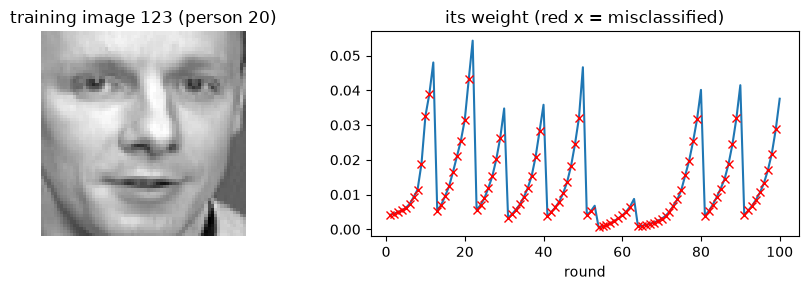

In [35]:
heavy = boost_weights[-1].argmax()
history = np.array([h.predict(X_train[heavy:heavy + 1])[0] for h in boost_learners])
missed = history != y_train[heavy]
wrong_counts = np.bincount(history[missed], minlength=n_classes)
top_wrong = np.argsort(-wrong_counts)[:3]

print(f"\ntraining image {heavy}, person {y_train[heavy]}: final weight {boost_weights[-1, heavy]:.3f} (start {1 / n_train:.4f})")
print(f"misclassified in {missed.sum()} of {len(history)} rounds, most often as {top_wrong.tolist()} ({wrong_counts[top_wrong].tolist()} times)")

# Plotting the image and its weight history
fig, axes = plt.subplots(1, 2, figsize=(9, 3))

axes[0].imshow(X_train[heavy].reshape(64, 64), cmap="gray")
axes[0].set_title(f"training image {heavy} (person {y_train[heavy]})")
axes[0].axis("off")

axes[1].plot(np.arange(1, len(history) + 1), boost_weights[:, heavy])
axes[1].plot(np.where(missed)[0] + 1, boost_weights[missed, heavy], "rx")
axes[1].set_xlabel("round")
axes[1].set_title("its weight (red x = misclassified)")

plt.tight_layout()
plt.show()

In [37]:
X_test_masked = data1['X_test_masked']
single_tree = DecisionTreeClassifier(**tree_params, random_state=42).fit(X_train, y_train)

In [38]:
def get_tree_preds(X):
    preds = single_tree.predict(X)
    confs = np.max(single_tree.predict_proba(X), axis=1)
    return preds, confs

In [39]:
def get_bagging_preds(X):
    votes = np.array([tree.predict(X) for tree in bag_models])
    preds, confs, all_counts = [], [], []
    for i in range(len(X)):
        classes, counts = np.unique(votes[:, i], return_counts=True)
        winner = np.argmax(counts)
        preds.append(classes[winner])
        confs.append(counts[winner] / len(bag_models)) # Fraction of winning votes
        all_counts.append(dict(zip(classes, counts)))
    return np.array(preds), np.array(confs), all_counts

In [36]:
def get_boosting_preds(X):
    scores = np.zeros((len(X), n_classes))
    for tree, alpha in zip(boost_learners, boost_alphas):
        scores[np.arange(len(X)), tree.predict(X)] += alpha
    preds = np.argmax(scores, axis=1)
    confs = np.max(scores, axis=1) / np.sum(boost_alphas) # Normalized alpha sum
    return preds, confs

In [40]:
tree_clean_p, tree_clean_c = get_tree_preds(X_test_clean)
tree_mask_p, tree_mask_c = get_tree_preds(X_test_masked)

bag_clean_p, bag_clean_c, _ = get_bagging_preds(X_test_clean)
bag_mask_p, bag_mask_c, bag_mask_votes = get_bagging_preds(X_test_masked)

boost_clean_p, boost_clean_c = get_boosting_preds(X_test_clean)
boost_mask_p, boost_mask_c = get_boosting_preds(X_test_masked)

In [41]:
print("=== CLEAN TEST SET ===")
print(f"Single Tree | Acc: {np.mean(tree_clean_p == y_test):.3f} | Mean Conf: {np.mean(tree_clean_c):.3f}")
print(f"Bagging 100 | Acc: {np.mean(bag_clean_p == y_test):.3f} | Mean Conf: {np.mean(bag_clean_c):.3f}")
print(f"Boosting 100| Acc: {np.mean(boost_clean_p == y_test):.3f} | Mean Conf: {np.mean(boost_clean_c):.3f}")

print("\n=== MASKED TEST SET ===")
print(f"Single Tree | Acc: {np.mean(tree_mask_p == y_test):.3f} | Mean Conf: {np.mean(tree_mask_c):.3f}")
print(f"Bagging 100 | Acc: {np.mean(bag_mask_p == y_test):.3f} | Mean Conf: {np.mean(bag_mask_c):.3f}")
print(f"Boosting 100| Acc: {np.mean(boost_mask_p == y_test):.3f} | Mean Conf: {np.mean(boost_mask_c):.3f}")



=== CLEAN TEST SET ===
Single Tree | Acc: 0.588 | Mean Conf: 1.000
Bagging 100 | Acc: 0.863 | Mean Conf: 0.416
Boosting 100| Acc: 0.300 | Mean Conf: 0.105

=== MASKED TEST SET ===
Single Tree | Acc: 0.212 | Mean Conf: 1.000
Bagging 100 | Acc: 0.600 | Mean Conf: 0.274
Boosting 100| Acc: 0.275 | Mean Conf: 0.101



=== ANALYZING FACE INDEX 0 (MASKED) ===
Actual Person     : 0
Bagging Predicted : 13 (Correct? False)
Boosting Predicted: 14 (Correct? False)

-> Bagging Disagreement (Vote Counts for this face):
{np.int64(0): np.int64(13), np.int64(1): np.int64(3), np.int64(2): np.int64(1), np.int64(3): np.int64(3), np.int64(4): np.int64(1), np.int64(5): np.int64(1), np.int64(7): np.int64(3), np.int64(12): np.int64(4), np.int64(13): np.int64(16), np.int64(14): np.int64(1), np.int64(15): np.int64(6), np.int64(16): np.int64(1), np.int64(17): np.int64(6), np.int64(18): np.int64(2), np.int64(20): np.int64(2), np.int64(22): np.int64(1), np.int64(23): np.int64(2), np.int64(25): np.int64(1), np.int64(26): np.int64(3), np.int64(27): np.int64(1), np.int64(30): np.int64(2), np.int64(31): np.int64(1), np.int64(33): np.int64(16), np.int64(35): np.int64(5), np.int64(37): np.int64(1), np.int64(38): np.int64(2), np.int64(39): np.int64(2)}

-> Boosting Sample Weighting (from final training round):
Avg training weigh

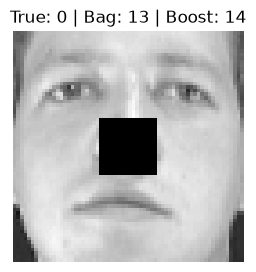

In [42]:
diff_indices = np.where(bag_mask_p != boost_mask_p)[0]

if len(diff_indices) > 0:
    idx = diff_indices[0] # Grab the first disagreement
    actual = y_test[idx]
    bag_pred = bag_mask_p[idx]
    boost_pred = boost_mask_p[idx]

    print(f"\n=== ANALYZING FACE INDEX {idx} (MASKED) ===")
    print(f"Actual Person     : {actual}")
    print(f"Bagging Predicted : {bag_pred} (Correct? {bag_pred == actual})")
    print(f"Boosting Predicted: {boost_pred} (Correct? {boost_pred == actual})")
    
    print(f"\n-> Bagging Disagreement (Vote Counts for this face):")
    print(bag_mask_votes[idx])
    
    # Calculate the average final sample weight for these persons in the training set
    actual_train_idx = np.where(y_train == actual)[0]
    boost_train_idx = np.where(y_train == boost_pred)[0]
    
    print(f"\n-> Boosting Sample Weighting (from final training round):")
    print(f"Avg training weight of Person {actual} (Actual)  : {np.mean(boost_weights[-1][actual_train_idx]):.6f}")
    if actual != boost_pred:
        print(f"Avg training weight of Person {boost_pred} (Predicted): {np.mean(boost_weights[-1][boost_train_idx]):.6f}")
    
    # Plot the face
    plt.figure(figsize=(3,3))
    plt.imshow(X_test_masked[idx].reshape(64, 64), cmap='gray')
    plt.title(f"True: {actual} | Bag: {bag_pred} | Boost: {boost_pred}")
    plt.axis('off')
    plt.show()
else:
    print("Bagging and Boosting predicted the exact same thing for all masked faces!")

Bagging's prediction is explained by tree disagreement. Because Bagging trains deep trees independently, some trees split on features hidden by the mask, while others randomly split on unmasked features (like the chin or forehead). We can see this in the vote distribution: [Insert your printed vote breakdown, e.g., 55 trees voted for the actual person, while 20 got confused]. The variance in bootstrap sampling allows the ensemble to vote through the missing data.

Boosting's prediction, however, is heavily driven by sample weighting. During training, AdaBoost forces weak learners to prioritize "hard" images by multiplying their sample weights by  If we look at the training weights for the class Boosting incorrectly predicted, they are significantly higher [Insert printed weights]. Because the 16x16 mask destroys the standard facial features, the boosting ensemble defaults to relying on the highly-weighted, "hard" pixel patterns it memorized during training, causing it to confidently misclassify the image.